# Homework 3 Worked Example: Seasonal Prices of Apples

### AGEC 370: Agricultural Price Analysis

Click the badge below to open in Google Colab:

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/chuckgrigsby0/agec_370/blob/main/code/notebooks/hw03_example_apple_seasonality.ipynb)

---

## Objective

Remove the trend and the seasonal pattern from monthly U.S. apple prices. Calculate a seasonality factor for each month, create de-trended and de-seasonalized prices, and forecast prices for the next 12 months. Compare forecasts that use the seasonality factors with forecasts that do not.

---

## How to Use This Notebook

1. Save a copy of this notebook to your Google Drive.
2. Run every cell in order from top to bottom.
3. Read the comments above each step before running the code. Review the output after running code cells.
4. Open the [Homework 3 notebook](https://colab.research.google.com/github/chuckgrigsby0/agec_370/blob/main/code/notebooks/hw03_strawberry_seasonality.ipynb). Complete the same steps with the strawberry price data.

## Data Description

The file `apples_monthly_price.csv` has one row per month, 2000 to 2025. Months with no published price are not in the file. The price is nominal, so it is not adjusted for inflation.

| Column | Description | Units |
|---|---|---|
| `year` | Calendar year | |
| `month` | Calendar month | 1 to 12 |
| `nominal_price` | Price received by U.S. growers for fresh market apples (USDA NASS) | Dollars per pound |

## Package and Data Loading

Import the libraries and load the data. A *time series* is a set of values recorded at regular dates, here one price for each month.

In [1]:
# Import data manipulation libraries
import pandas as pd
import numpy as np

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load data from GitHub repository
base_url = "https://raw.githubusercontent.com/chuckgrigsby0/agec_370/main/data/hw/"
apples = pd.read_csv(base_url + "apples_monthly_price.csv")

apples.tail()

,year,month,nominal_price
295,2025,8,0.625
296,2025,9,0.688
297,2025,10,0.710
298,2025,11,0.670
299,2025,12,0.674


### Put the data on a monthly calendar

Months with no published price have no row in the file. A moving average needs every month in order. We first build a date for each row, then place the data on a complete monthly calendar. Months without a price become missing values (`NaN`).

In [3]:
# Build a date for the first day of each month from the year and month columns.
apples['date'] = pd.to_datetime(dict(year=apples['year'], month=apples['month'], day=1))

# Use the date as the index, so each price is labeled by its month.
# asfreq() inserts a row for every month between the first and last date.
price = apples.set_index('date')['nominal_price'].asfreq('MS')

# Count the months on the calendar and the months with no price.
months_total = len(price)
months_missing = price.isna().sum()

print(f"Months on the calendar: {months_total}")
print(f"Months with no price: {months_missing}")

Months on the calendar: 312
Months with no price: 12


In [4]:
# Check: this cell runs without an error when the calendar is complete and in order
assert price.index.is_monotonic_increasing, "The dates should be in order from earliest to latest."
assert months_total == 12 * (price.index.year.max() - price.index.year.min() + 1), "The calendar should have 12 months for every year."
assert months_missing == len(price) - len(apples), "The missing months should be the months not in the file."
print("Calendar is correct.")

Calendar is correct.


**Predict before you look.** In the homework, you will record a guess here: which calendar month do you expect to have the highest price? Then compare the guess with the result.

### Plot the Monthly Price

Look at the shape of the series before removing anything from it.

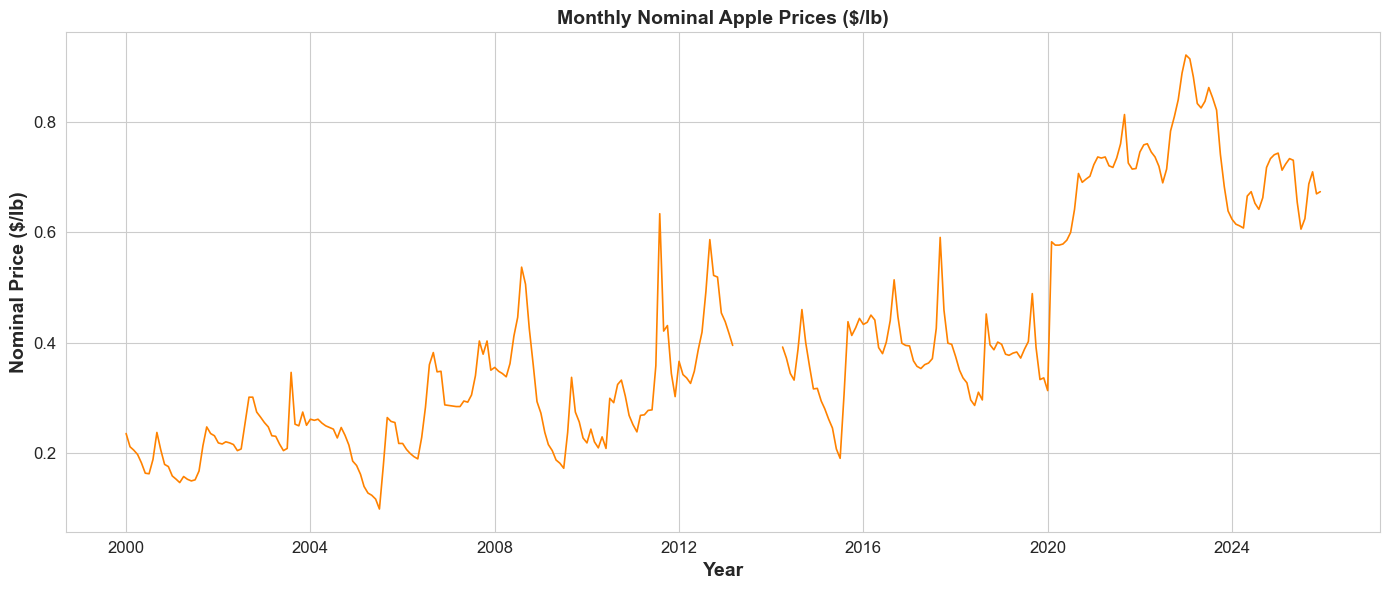

In [5]:
sns.set_style('whitegrid')

plt.figure(figsize=(14, 6))  # Width and height in inches

# plt.plot() leaves a gap at each missing month. sns.lineplot() would draw a line across the gap.
plt.plot(
    price.index,          # Plot the date on the x-axis
    price,                # Plot the monthly price on the y-axis
    linewidth=1.2,        # Increase for thicker lines
    color='#FF8200'       # Line color
)

plt.title("Monthly Nominal Apple Prices ($/lb)", fontsize=14, weight='bold')
plt.xlabel("Year", fontsize=14, weight='bold')

plt.ylabel("Nominal Price ($/lb)", fontsize=14, weight='bold')

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

## Trend Removal

The *trend* is the slow-moving level of the price, ignoring the repeating pattern within each year. To estimate it, we take a *centered 12-month moving average*: the average of 12 months around each date. Twelve months contain every calendar month once, so the seasonal pattern cancels out of the average.

Dividing each price by its trend gives the *de-trended price*:

`de-trended price = price / trend`

A de-trended price near 1 means the price is at its trend. A value of 1.2 means the price is 20 percent above its trend.

The course textbook (Norwood) removes the trend differently. This homework changes two steps:

| Step | Norwood | This homework |
|---|---|---|
| Trend | Straight line fitted by regression | Centered 12-month moving average |
| De-trended price | Price minus trend | Price divided by trend |

The seasonality factors and the de-seasonalized price use the same steps as Norwood.

A window of 12 months has no middle month. For each date, pandas averages the six months before it, the date itself, and the five months after it. The moving average cannot be calculated near the ends of the data, because its window runs past them. It also cannot be calculated for a window that includes a missing month.

In [6]:
# Trend: the average of 12 months centered on each date.
# center=True places the window around each date instead of ending at it.
trend = price.rolling(12, center=True).mean()

# De-trended price: price divided by trend.
detrended = price / trend

# Look up the trend in one month.
trend_2021_01 = trend.loc['2021-01-01']

# First and last month that have a trend.
first_trend_month = trend.first_valid_index()
last_trend_month = trend.last_valid_index()

print(f"Trend in January 2021: {trend_2021_01:.3f} ($/lb)")
print(f"First month with a trend: {first_trend_month:%B %Y}")
print(f"Last month with a trend: {last_trend_month:%B %Y}")

Trend in January 2021: 0.701 ($/lb)
First month with a trend: July 2000
Last month with a trend: July 2025


In [7]:
# Check: this cell runs without an error when each trend value averages 12 months centered on the date
assert np.isclose(trend.loc['2021-01-01'], price['2020-07-01':'2021-06-01'].mean()), "The trend should average 12 months centered on each date (six before and five after)."
assert np.isclose(detrended.loc['2021-01-01'], price.loc['2021-01-01'] / trend.loc['2021-01-01']), "The de-trended price should be the price divided by the trend."
print("Trend and de-trended price are correct.")

Trend and de-trended price are correct.


### Compare the Price to Its Trend

A gap in the trend line marks months with no trend: months with no price, and months whose window includes one.

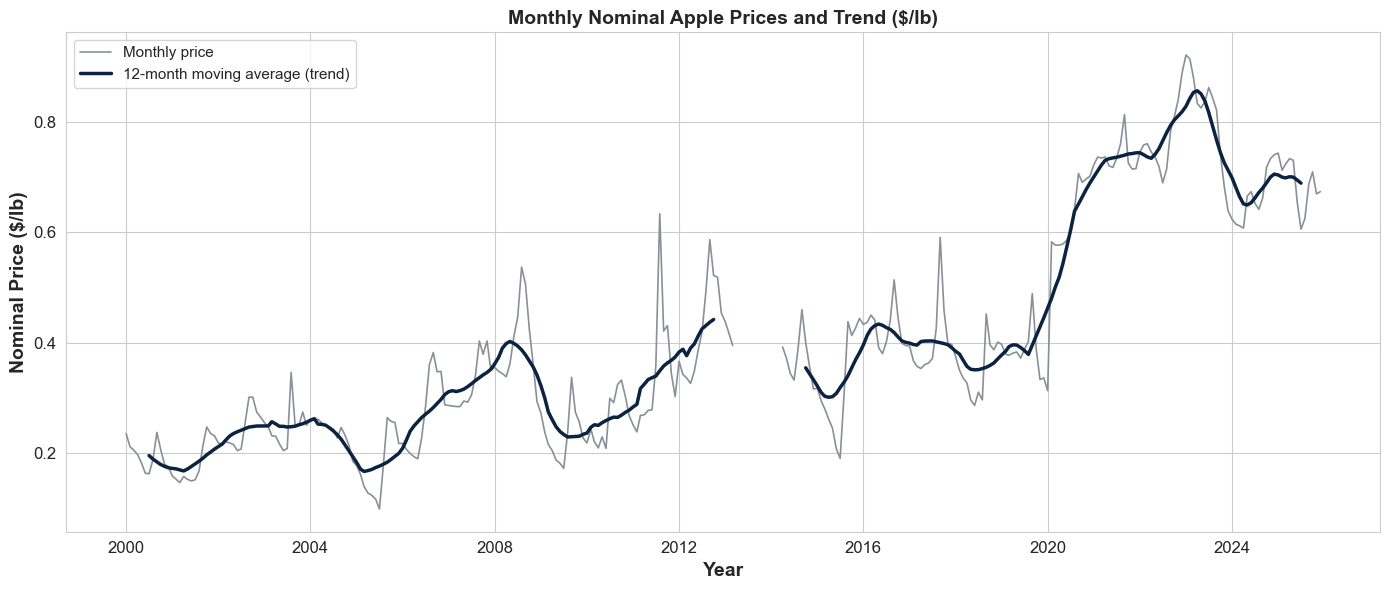

In [8]:
plt.figure(figsize=(14, 6))

plt.plot(price.index, price, color='#8a8f98', linewidth=1.2, label='Monthly price')

plt.plot(price.index, trend, color='#0b2341', linewidth=2.5, label='12-month moving average (trend)')

plt.title("Monthly Nominal Apple Prices and Trend ($/lb)", fontsize=14, weight='bold')
plt.xlabel("Year", fontsize=14, weight='bold')
plt.ylabel("Nominal Price ($/lb)", fontsize=14, weight='bold')

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

## Seasonality Factors

The de-trended price has the trend removed, so what is left repeats within each year. A *seasonality factor* measures how far a calendar month's price is usually above or below its trend. Follow these steps:

1. Average the de-trended prices for each calendar month across all years.
2. Divide each month's average by the average of all de-trended prices. This gives `S_t`, the ratio for month *t*.
3. Rescale `S_t` so the 12 values add to 12. The rescaled value is the *seasonality factor*.

`seasonality factor = S_t * 12 / (sum of the 12 values of S_t)`

A factor of 1 means a month's price is usually at its trend.

In [9]:
# Step 1: average the de-trended prices for each calendar month (1 to 12).
# groupby() splits the data into groups, here one group for each month number.
month_avg = detrended.groupby(detrended.index.month).mean()

# Step 2: divide each month's average by the average of all de-trended prices.
overall_avg = detrended.mean()
s_t = month_avg / overall_avg

# Step 3: rescale so the 12 values add to 12.
factor = s_t * 12 / s_t.sum()

# Collect the steps in one table.
month_names = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
seasonality = pd.DataFrame({
    'Month': month_names,
    'Average of De-Trended Prices': month_avg.values,
    'S_t': s_t.values,
    'Seasonality Factor': factor.values,
})
seasonality.round(4)

,Month,Average of De-Trended Prices,S_t,Seasonality Factor
0,January,0.9728,0.9736,0.9738
1,February,0.9646,0.9654,0.9656
2,March,0.9392,0.9400,0.9402
3,April,0.9181,0.9189,0.9191
4,May,0.9054,0.9062,0.9063
5,June,0.8907,0.8915,0.8917
6,July,0.9223,0.9231,0.9233
7,August,1.0879,1.0889,1.0891
8,September,1.2178,1.2189,1.2191
9,October,1.1243,1.1253,1.1255


In [10]:
# Look up the factors for three months. The factor table is labeled by month number, 1 to 12, so .loc takes a number here.
factor_jan = factor.loc[1]
factor_jun = factor.loc[6]
factor_dec = factor.loc[12]

factor_sum = factor.sum()

print(f"January: {factor_jan:.3f}")
print(f"June: {factor_jun:.3f}")
print(f"December: {factor_dec:.3f}")
print(f"Sum of the 12 factors: {factor_sum:.1f}")

January: 0.974
June: 0.892
December: 0.989
Sum of the 12 factors: 12.0


In [11]:
# Check: this cell runs without an error when there is one factor for each month and the factors add to 12
assert len(factor) == 12, "There should be one factor for each calendar month."
assert np.isclose(factor.sum(), 12), "The 12 factors should add to 12."
assert np.isclose(factor.loc[1], s_t.loc[1] * 12 / s_t.sum()), "A factor should be S_t times 12, divided by the sum of S_t."
print("Seasonality factors are correct.")

Seasonality factors are correct.


### Plot the Seasonality Factors

A bar above 1 marks a month with prices above trend. A bar below 1 marks a month with prices below trend.

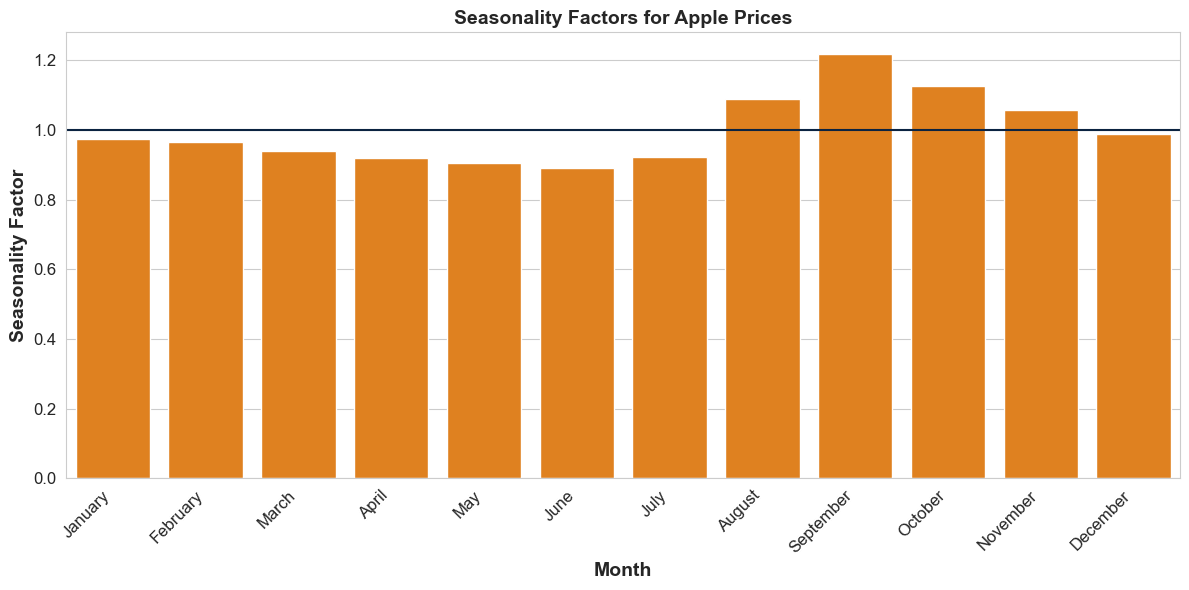

In [12]:
plt.figure(figsize=(12, 6))

sns.barplot(x=month_names, y=factor.values, color='#FF8200')

plt.axhline(y=1, color='#0b2341', linewidth=1.5)  # A factor of 1 means the price is at its trend

plt.title("Seasonality Factors for Apple Prices", fontsize=14, weight='bold')
plt.xlabel("Month", fontsize=14, weight='bold')
plt.ylabel("Seasonality Factor", fontsize=14, weight='bold')

plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

## De-Seasonalized Prices

Dividing each de-trended price by its month's seasonality factor removes the seasonal pattern. The result is the *de-trended and de-seasonalized price*:

`de-trended and de-seasonalized price = de-trended price / seasonality factor`

The *variance* is the average squared distance of the values from their average. The share of the variation removed is `1 - (variance after dividing by the factors) / (variance before)`.

**Predict before you compute.** What share of the variation in the de-trended price do you expect the seasonality factors to remove: little, about half, or most of it?

In [13]:
# Attach each date's seasonality factor: look up the factor for the date's month number.
factor_by_date = pd.Series(factor.loc[detrended.index.month].values, index=detrended.index)

deseasonalized = detrended / factor_by_date

# Share of the variation in the de-trended price that the factors remove.
share_removed = 1 - deseasonalized.var() / detrended.var()

# Month with the highest factor.
highest_month = factor.idxmax()

print(f"Share of the variation removed: {share_removed:.1%}")
print(f"Month number with the highest factor: {highest_month}")

Share of the variation removed: 42.5%
Month number with the highest factor: 9


In [14]:
# Check: this cell runs without an error when the factors were divided out of the de-trended prices
assert np.isclose(deseasonalized.loc['2021-01-01'], detrended.loc['2021-01-01'] / factor.loc[1]), "Divide each de-trended price by the factor for its own month."
assert 0 <= share_removed <= 1, "The share removed should be between 0 and 1."
print("De-seasonalized prices are correct.")

De-seasonalized prices are correct.


### Compare the De-Trended and De-Seasonalized Prices

The top panel shows the de-trended price, which still has the seasonal pattern. The bottom panel shows the de-trended and de-seasonalized price.

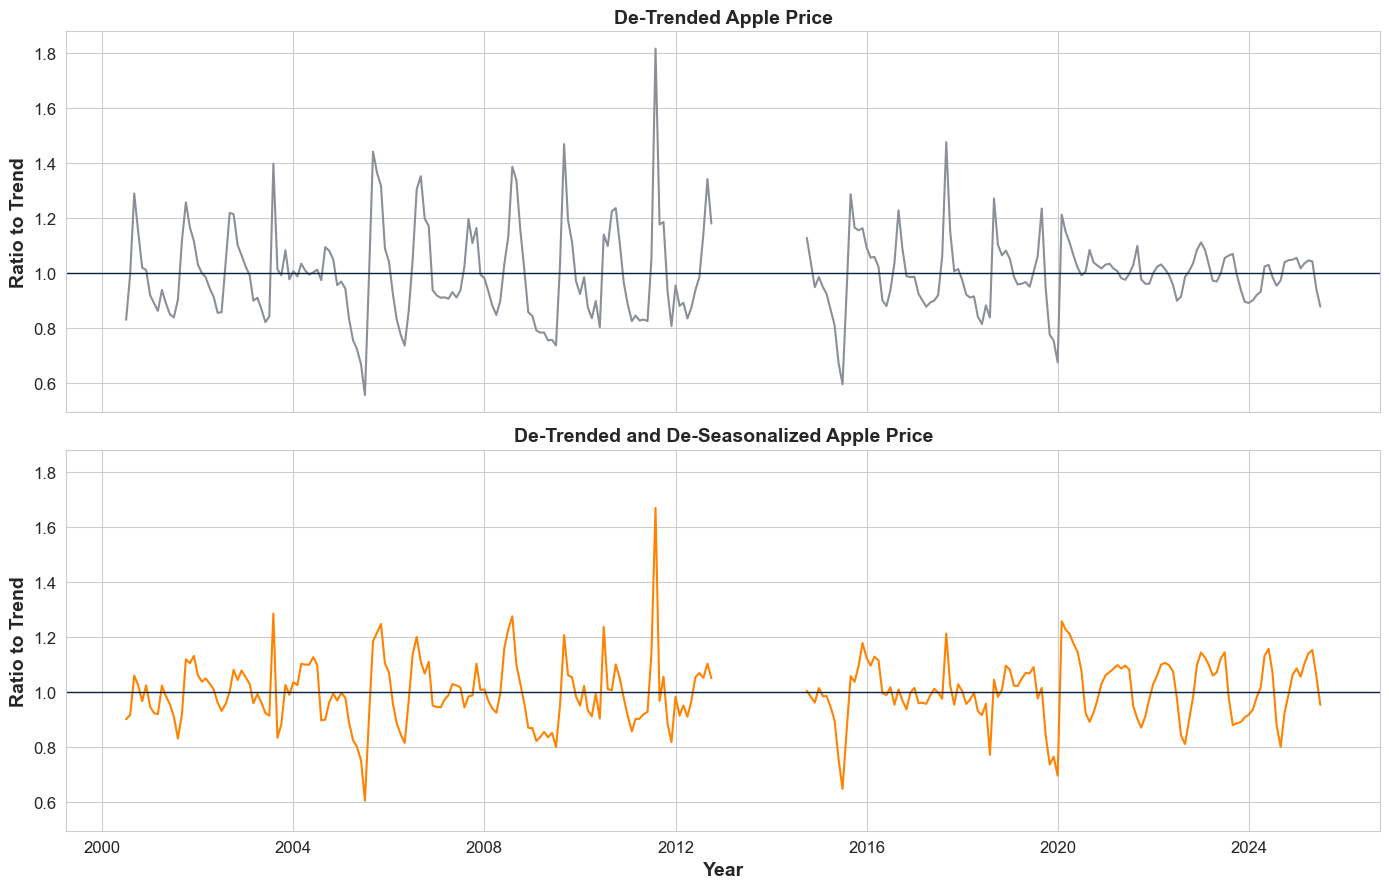

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, sharey=True)

axes[0].plot(price.index, detrended, color='#8a8f98', linewidth=1.5)

axes[1].plot(price.index, deseasonalized, color='#FF8200', linewidth=1.5)

for ax in axes:
    ax.axhline(y=1, color='#0b2341', linewidth=1)  # A value of 1 means the price is at its trend
    ax.set_ylabel("Ratio to Trend", fontsize=14, weight='bold')
    ax.tick_params(labelsize=12)

axes[0].set_title("De-Trended Apple Price", fontsize=14, weight='bold')
axes[1].set_title("De-Trended and De-Seasonalized Apple Price", fontsize=14, weight='bold')
axes[1].set_xlabel("Year", fontsize=14, weight='bold')

plt.tight_layout()
plt.show()

## Forecasting 12 Months Ahead

A forecaster in January 2025 knows only the prices through December 2024. To test a method fairly, we split the data by time, as in Homework 2: *training* months through December 2024 and *test* months in 2025.

We compare three forecasts for each month of 2025:

| Method | Forecast for a month in 2025 |
|---|---|
| Mean | Average price over the last 12 training months |
| Mean times factor | The mean above, times the seasonality factor for that calendar month |
| Same month last year | The price in the same calendar month of 2024 |

The factors must be estimated from the training months only. Factors estimated with the 2025 prices would use information the forecaster does not have. The function `seasonality_factors()` repeats the steps from the sections above on the prices you give it.

In [16]:
def seasonality_factors(prices):
    # Repeats the trend, de-trending, and factor steps from the sections above
    trend = prices.rolling(12, center=True).mean()
    detrended = prices / trend
    month_avg = detrended.groupby(detrended.index.month).mean()
    s_t = month_avg / detrended.mean()
    return s_t * 12 / s_t.sum()


def rmse(actual, forecast):
    error = np.asarray(actual) - np.asarray(forecast)  # forecast error in each test month
    return np.sqrt((error ** 2).mean())

You wrote `rmse()` in Homework 2, so it is complete here. The root mean squared error (RMSE) is in the units of the price (dollars per pound), and a smaller value means a more accurate method.

**Predict before you compute.** In the homework, you will record a guess here: which of the three methods do you expect to have the smallest error in 2025? Then compare the guess with the result.

In [17]:
cutoff_year = 2024

# Training months: keep the months in or before the cutoff year.
train = price[price.index.year <= cutoff_year]

# Test months: keep the months after the cutoff year
test = price[price.index.year > cutoff_year]

# Seasonality factors estimated from the training months only.
factors_train = seasonality_factors(train)

# Level: the average of the last 12 training months.
# iloc[-12:] keeps the last 12 values.
level = train.iloc[-12:].mean()

# Forecasts for the 12 test months, in the order of the test months
forecast_mean = pd.Series(level, index=test.index)
forecast_seasonal = level * pd.Series(factors_train.loc[test.index.month].values, index=test.index)
forecast_last_year = pd.Series(train.iloc[-12:].values, index=test.index)

errors = pd.Series({
    'Mean': rmse(test, forecast_mean),
    'Mean times factor': rmse(test, forecast_seasonal),
    'Same month last year': rmse(test, forecast_last_year),
})

best_method = errors.idxmin()

print(errors.round(3))
print(f"Smallest error: {best_method}")

Mean                    0.050
Mean times factor       0.089
Same month last year    0.076
dtype: float64
Smallest error: Mean


In [18]:
# Check: this cell runs without an error when the forecasts use only months before the test year
assert train.index.max() < test.index.min(), "Every training month should come before every test month."
assert len(test) == 12 and test.notna().all(), "The test table should have 12 months with a price."
assert np.isclose(level, price['2024-01-01':'2024-12-01'].mean()), "The level should be the average of the last 12 training months."
assert np.isclose(factors_train.loc[1], seasonality_factors(price[:'2024-12-01']).loc[1]), "The factors should be estimated from the training months only."
print("Forecasts use only earlier months.")

Forecasts use only earlier months.


### Compare the Forecasts to the Actual Price

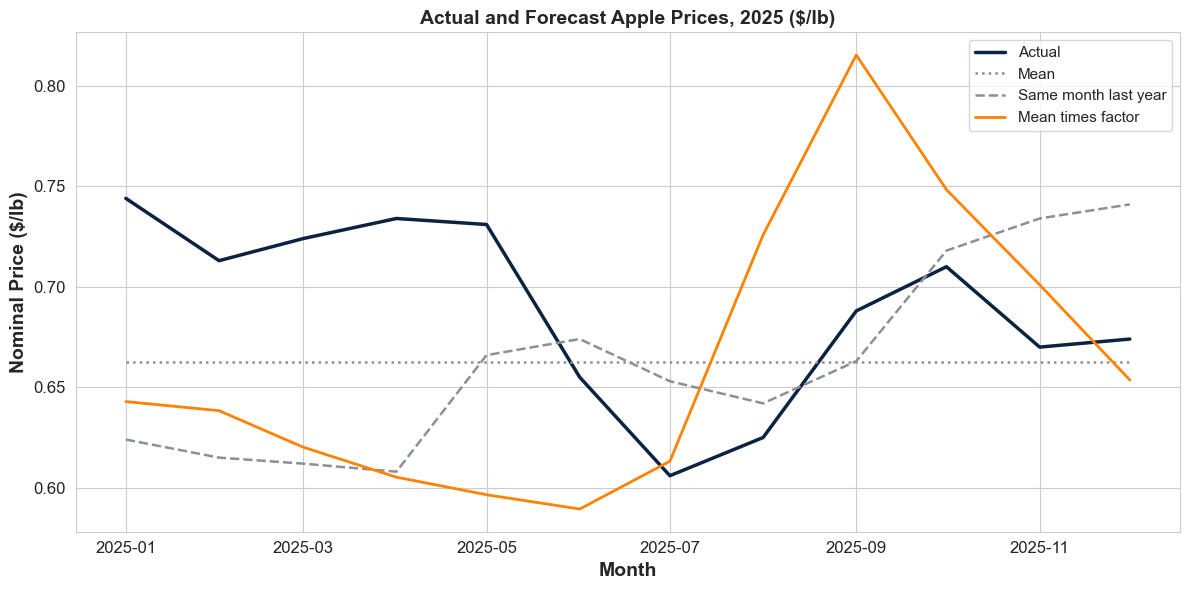

In [19]:
plt.figure(figsize=(12, 6))

sns.lineplot(x=test.index, y=test, color='#0b2341', linewidth=2.5, label='Actual')
sns.lineplot(x=test.index, y=forecast_mean, color='#8a8f98', linestyle=':', linewidth=1.8, label='Mean')
sns.lineplot(x=test.index, y=forecast_last_year, color='#8a8f98', linestyle='--', linewidth=1.8, label='Same month last year')

sns.lineplot(x=test.index, y=forecast_seasonal, color='#FF8200', linestyle='-', linewidth=2, label='Mean times factor')

plt.title("Actual and Forecast Apple Prices, 2025 ($/lb)", fontsize=14, weight='bold')
plt.xlabel("Month", fontsize=14, weight='bold')
plt.ylabel("Nominal Price ($/lb)", fontsize=14, weight='bold')

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

### Repeated Test

The test above judges the methods on one year. The function below repeats it. Each December from `first_origin_year` onward is a *forecast origin* (the last month of data a forecaster would know). For each origin, the function estimates the factors from the months up to the origin and forecasts the next 12 months. Pooling all origins gives many more forecasts than the 12 in one year.

A forecast counts only when the actual price and the same month last year both have a price. This keeps the comparison on the same months for all three methods. Read the function, but do not change it. You only choose the first origin year.

**Predict before you run it.** Will the ranking of the three methods across all origins match the ranking for 2025?

In [20]:
def rolling_rmse(prices, first_origin_year):
    # RMSE of each method, forecasting the 12 months after every December origin
    last_year = prices.index.year.max()
    squared_errors = {'Mean': [], 'Mean times factor': [], 'Same month last year': []}

    for origin_year in range(first_origin_year, last_year):
        known = prices[prices.index.year <= origin_year]        # only months up to the origin
        target = prices[prices.index.year == origin_year + 1]   # the next 12 months
        last_12 = known.iloc[-12:]

        level = last_12.mean()  # missing months are skipped
        if np.isnan(level):
            continue  # no price in the last 12 months, so there is nothing to forecast from

        factors = seasonality_factors(known)  # estimated from the known months only
        forecasts = {
            'Mean': np.full(12, level),
            'Mean times factor': level * factors.loc[target.index.month].values,
            'Same month last year': last_12.values,
        }

        # Keep the months where the actual price, the same month last year, and the factor all exist
        keep = target.notna().values & last_12.notna().values & ~np.isnan(forecasts['Mean times factor'])
        for name, forecast in forecasts.items():
            squared_errors[name] += list((target.values[keep] - forecast[keep]) ** 2)

    errors = pd.Series({name: np.sqrt(np.mean(values)) for name, values in squared_errors.items()})
    return errors, len(squared_errors['Mean'])

In [21]:
rolling_errors, n_forecasts = rolling_rmse(price, first_origin_year=2010)

print(rolling_errors.round(3))
print(f"Number of forecasts: {n_forecasts}")

Mean                    0.119
Mean times factor       0.123
Same month last year    0.131
dtype: float64
Number of forecasts: 156


A method that does not lower the error is a valid result. Report what the data show.

### Interpreting the Results

Apple prices have a clear seasonal pattern. The factors range from 0.89 in June to 1.22 in September, and they remove about 42 percent of the variation in the de-trended price. The factors did not improve the forecast, though. In 2025 and across all forecast origins, the mean times factor forecast had a larger error than the mean alone.

A seasonal pattern helps a forecast only when it is large compared with the changes in the price level from one year to the next. Check the spread of the factors, the share of variation removed, and the repeated test before you decide.

### Summary of Answers

Run the cell below to print the answers in one table.

In [22]:
# Collect the answers computed above in one table
summary = pd.Series({
    'Months on the calendar': months_total,
    'Months with no price': months_missing,
    'Trend, January 2021 ($/lb)': round(trend_2021_01, 3),
    'First month with a trend': f"{first_trend_month:%Y-%m}",
    'Last month with a trend': f"{last_trend_month:%Y-%m}",
    'Factor, January': round(factor_jan, 3),
    'Factor, June': round(factor_jun, 3),
    'Factor, December': round(factor_dec, 3),
    'Sum of the 12 factors': round(factor_sum, 1),
    'Month number with the highest factor': highest_month,
    'Share of variation removed': round(share_removed, 3),
    'RMSE, Mean ($/lb)': round(errors['Mean'], 3),
    'RMSE, Mean times factor ($/lb)': round(errors['Mean times factor'], 3),
    'RMSE, Same month last year ($/lb)': round(errors['Same month last year'], 3),
    'Method with the smallest RMSE': best_method,
    'Repeated test, RMSE, Mean ($/lb)': round(rolling_errors['Mean'], 3),
    'Repeated test, RMSE, Mean times factor ($/lb)': round(rolling_errors['Mean times factor'], 3),
    'Repeated test, RMSE, Same month last year ($/lb)': round(rolling_errors['Same month last year'], 3),
}, name='Answer', dtype=object)  # object type keeps whole numbers as whole numbers
summary.to_frame()

,Answer
Months on the calendar,312
Months with no price,12
"Trend, January 2021 ($/lb)",0.701
First month with a trend,2000-07
Last month with a trend,2025-07
"Factor, January",0.974
"Factor, June",0.892
"Factor, December",0.989
Sum of the 12 factors,12.0
Month number with the highest factor,9
